<a href="https://colab.research.google.com/github/FarzanaAkter123/AI-Search-Algorithms/blob/main/bfs.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

BFS Traversal Order: ['A', 'B', 'C', 'D', 'E', 'F', 'G']
Shortest Path: ['A', 'C', 'G']
Path Length: 2


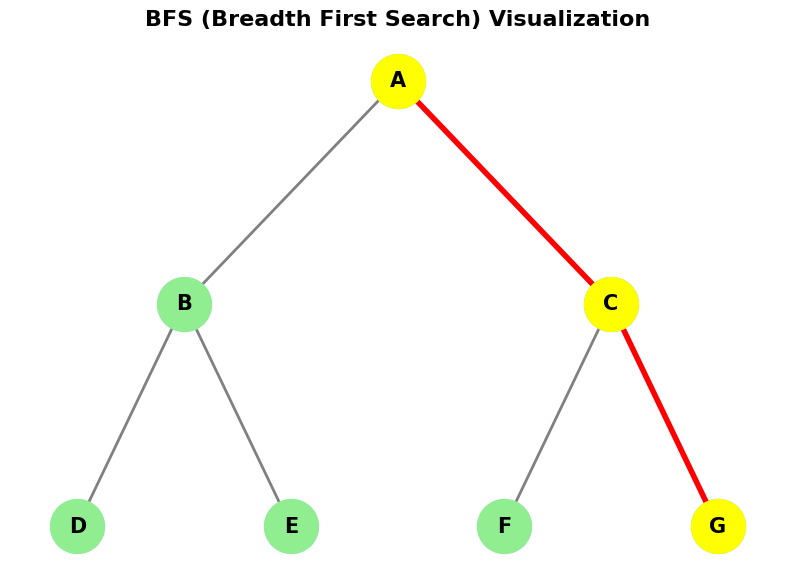

In [ ]:
import networkx as nx
import matplotlib.pyplot as plt
from collections import deque

# Create Graph
G = nx.Graph()

edges = [
    ('A', 'B'),
    ('A', 'C'),
    ('B', 'D'),
    ('B', 'E'),
    ('C', 'F'),
    ('C', 'G')
]

G.add_edges_from(edges)

# BFS Algorithm
def bfs(graph, start, goal):

    visited = set()
    queue = deque([[start]])
    bfs_order = []

    while queue:

        path = queue.popleft()
        node = path[-1]

        if node not in visited:

            visited.add(node)
            bfs_order.append(node)

            if node == goal:
                return bfs_order, path

            for neighbor in graph.neighbors(node):

                if neighbor not in visited:
                    new_path = list(path)
                    new_path.append(neighbor)
                    queue.append(new_path)

    return bfs_order, None


# Start and Goal
start = 'A'
goal = 'G'

# Run BFS
bfs_order, path = bfs(G, start, goal)

# Print Results
print("BFS Traversal Order:", bfs_order)
print("Shortest Path:", path)
print("Path Length:", len(path) - 1)


# Visualization
pos = {
    'A': (0, 2),
    'B': (-1, 1),
    'C': (1, 1),
    'D': (-1.5, 0),
    'E': (-0.5, 0),
    'F': (0.5, 0),
    'G': (1.5, 0)
}

plt.figure(figsize=(10, 7))

# Draw all nodes
nx.draw_networkx_nodes(
    G, pos,
    node_color='lightblue',
    node_size=1500
)

# Draw all edges
nx.draw_networkx_edges(
    G, pos,
    edge_color='gray',
    width=2
)

# Draw labels
nx.draw_networkx_labels(
    G, pos,
    font_size=15,
    font_weight='bold'
)

# Highlight visited nodes
nx.draw_networkx_nodes(
    G, pos,
    nodelist=bfs_order,
    node_color='lightgreen',
    node_size=1500
)

# Highlight shortest path
if path:

    path_edges = list(zip(path, path[1:]))

    nx.draw_networkx_nodes(
        G, pos,
        nodelist=path,
        node_color='yellow',
        node_size=1500
    )

    nx.draw_networkx_edges(
        G, pos,
        edgelist=path_edges,
        edge_color='red',
        width=4
    )

plt.title(
    "BFS (Breadth First Search) Visualization",
    fontsize=16,
    fontweight='bold'
)

plt.axis('off')
plt.show()